✅ Data loaded successfully!

📊 Dataset Shape: (74711, 31)
📈 Loss Statistics:
count    74711.000000
mean         0.284959
std          0.191496
min          0.030000
25%          0.092000
50%          0.340000
75%          0.500000
max          0.550000
Name: loss, dtype: float64


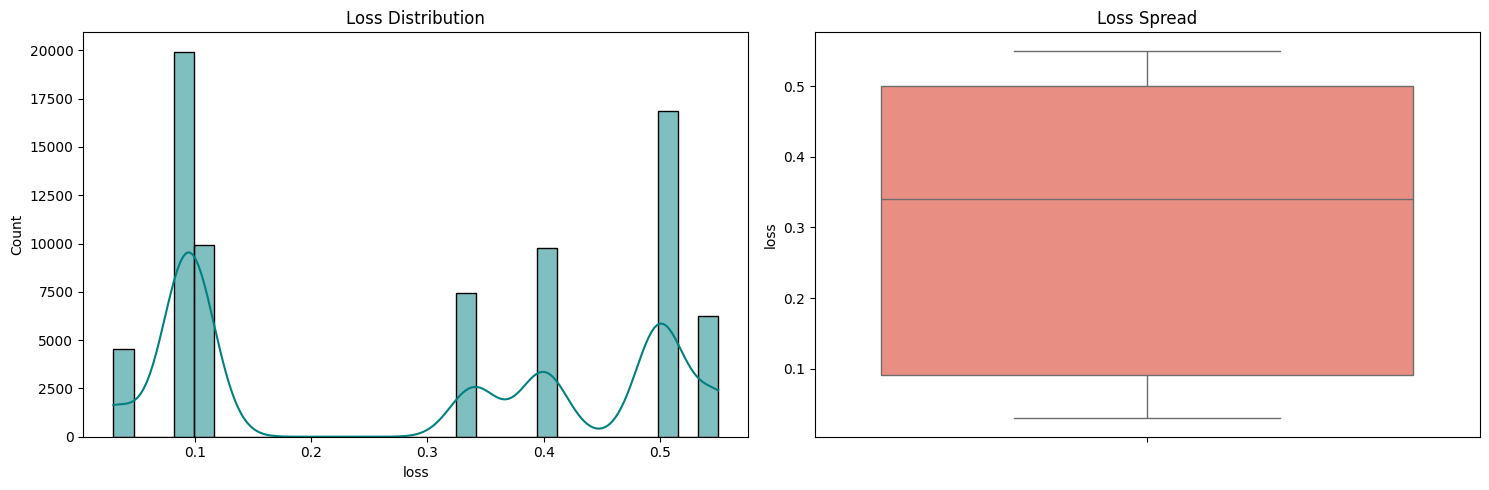


🔢 Training samples: 59768
🔢 Testing samples: 14943

⏳ Optimizing model...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates

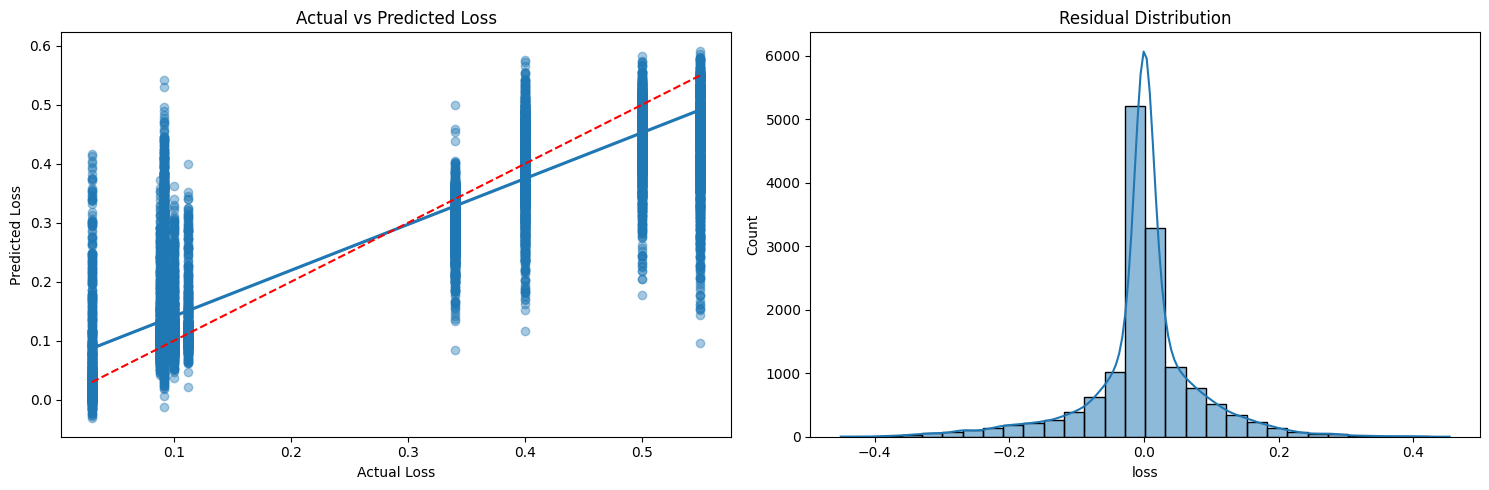

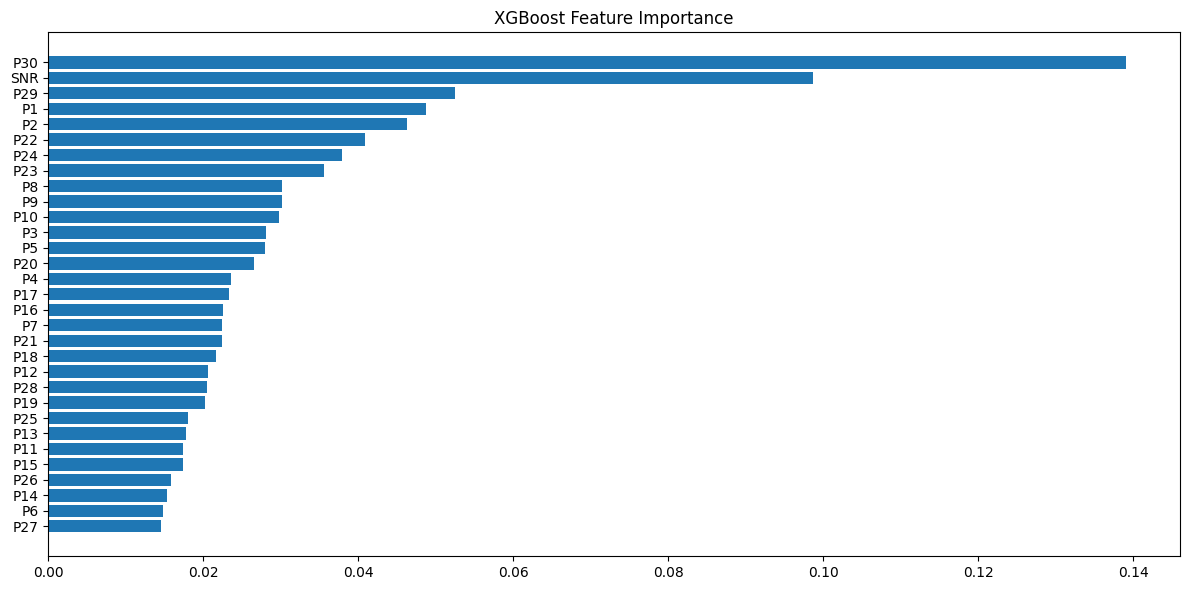


🔍 Computing SHAP values...


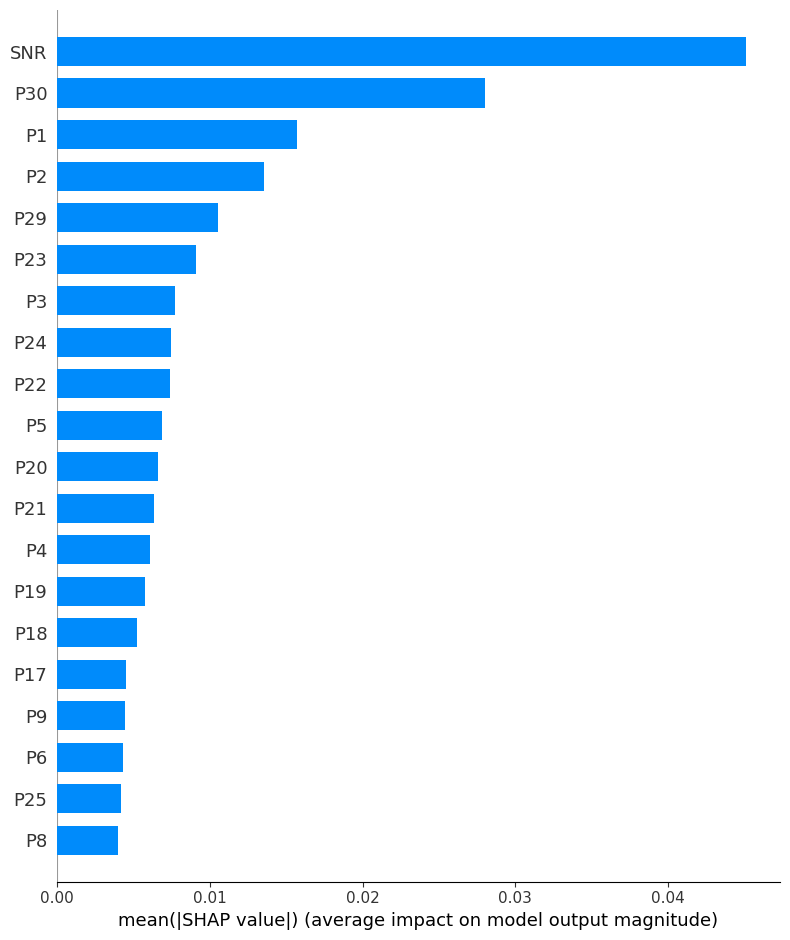

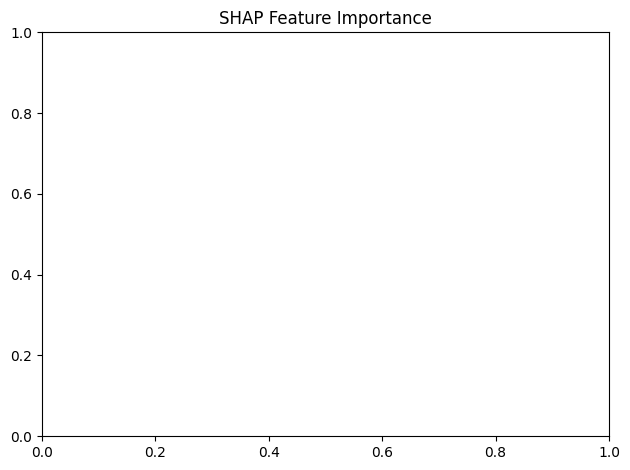


💾 Saved Artifacts:
- Model: loss_model_v20250810_1748.pkl
- Metrics: loss_metrics_v20250810_1748.json
- Parameters: loss_params_v20250810_1748.json

🔮 Example Prediction:
Input Features:
+-------+-------+------------+------------+------------+------------+------------+------+------------+------------+------------+------------+------------+------------+-----------+------------+------------+------------+-----------+-----------+----------+----------+----------+----------+----------+----------+----------+---------+----------+----------+-------+----------+
|       |   SNR |         P1 |         P2 |         P3 |         P4 |         P5 |   P6 |         P7 |         P8 |         P9 |        P10 |        P11 |        P12 |       P13 |        P14 |        P15 |        P16 |       P17 |       P18 |      P19 |      P20 |      P21 |      P22 |      P23 |      P24 |      P25 |     P26 |      P27 |      P28 |   P29 |      P30 |
+=======+=======+============+============+============+============+=

In [ ]:
# %% [markdown]
## 🌟 Optical Fiber Loss Prediction Model
# XGBoost with Bayesian Hyperparameter Tuning

# %%
!pip install xgboost scikit-optimize shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from xgboost import XGBRegressor
from skopt import BayesSearchCV
from skopt.space import Real, Integer
import joblib
import shap
import warnings
warnings.filterwarnings("ignore")

# Configuration
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# %% [markdown]
### 📥 1. Data Loading & Cleaning
# %%
def load_and_clean_data(filepath):
    try:
        df = pd.read_csv(filepath, on_bad_lines='warn')
        print("✅ Data loaded successfully!")

        # Verify required columns
        required_features = ['SNR'] + [f'P{i}' for i in range(1, 31)]
        required_target = 'loss'
        assert all(col in df.columns for col in required_features + [required_target]), "Missing required columns"

        # Clean data
        df = df.dropna(subset=[required_target])
        for col in required_features:
            df[col] = df[col].fillna(df[col].median())

        # Remove outliers (top/bottom 2%)
        q_low = df[required_target].quantile(0.02)
        q_high = df[required_target].quantile(0.98)
        df = df[(df[required_target] > q_low) & (df[required_target] < q_high)]

        return df[required_features], df[required_target]

    except Exception as e:
        print(f"❌ Error: {str(e)}")
        raise

X, y = load_and_clean_data('OTDR_dataset.csv')

# %% [markdown]
### 🔍 2. Exploratory Data Analysis
# %%
print(f"\n📊 Dataset Shape: {X.shape}")
print(f"📈 Loss Statistics:\n{y.describe()}")

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.histplot(y, bins=30, kde=True, color='teal')
plt.title('Loss Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(y=y, color='salmon')
plt.title('Loss Spread')
plt.tight_layout()
plt.show()

# %% [markdown]
### ⚙ 3. Train-Test Split
# %%
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print(f"\n🔢 Training samples: {X_train.shape[0]}")
print(f"🔢 Testing samples: {X_test.shape[0]}")

# %% [markdown]
### 🤖 4. Bayesian-Optimized XGBoost
# %%
search_space = {
    'n_estimators': Integer(50, 300),
    'max_depth': Integer(3, 8),
    'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
    'subsample': Real(0.6, 1.0),
    'colsample_bytree': Real(0.6, 1.0),
    'gamma': Real(0, 2),
    'reg_alpha': Real(1e-6, 10, prior='log-uniform'),
    'reg_lambda': Real(1e-6, 10, prior='log-uniform'),
}

model = XGBRegressor(
    objective='reg:squarederror',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    tree_method='hist'
)

opt = BayesSearchCV(
    estimator=model,
    search_spaces=search_space,
    n_iter=40,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=RANDOM_STATE,
    verbose=1
)

# %% [markdown]
### 🚀 5. Model Training
# %%
print("\n⏳ Optimizing model...")
opt.fit(X_train, y_train)

best_params = opt.best_params_
print(f"\n✅ Best Parameters:\n{pd.Series(best_params).to_markdown()}")

final_model = XGBRegressor(
    **best_params,
    objective='reg:squarederror',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    early_stopping_rounds=20,
    eval_metric='rmse'
)

print("\n🏋 Training final model...")
final_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=20
)

# %% [markdown]
### 📊 6. Model Evaluation
# %%
def calculate_metrics(y_true, y_pred, prefix=''):
    return {
        f'{prefix}RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        f'{prefix}MAE': mean_absolute_error(y_true, y_pred),
        f'{prefix}R2': r2_score(y_true, y_pred),
        f'{prefix}MAPE': np.mean(np.abs((y_true - y_pred)/y_true)) * 100
    }

metrics = {}
metrics.update(calculate_metrics(y_train, final_model.predict(X_train), 'train_'))
metrics.update(calculate_metrics(y_test, final_model.predict(X_test), 'test_'))

print("\n📈 Performance Metrics:")
print(pd.DataFrame([metrics]).to_markdown(floatfmt=".6f", tablefmt="grid"))

# Visualization
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.regplot(x=y_test, y=final_model.predict(X_test), scatter_kws={'alpha':0.4})
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.title('Actual vs Predicted Loss')
plt.xlabel('Actual Loss')
plt.ylabel('Predicted Loss')

plt.subplot(1, 2, 2)
residuals = y_test - final_model.predict(X_test)
sns.histplot(residuals, bins=30, kde=True)
plt.title('Residual Distribution')
plt.tight_layout()
plt.show()

# %% [markdown]
### 🔍 7. Model Interpretation
# %%
# Feature Importance
plt.figure(figsize=(12, 6))
sorted_idx = final_model.feature_importances_.argsort()
plt.barh(X.columns[sorted_idx], final_model.feature_importances_[sorted_idx])
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

# SHAP Analysis
print("\n🔍 Computing SHAP values...")
explainer = shap.Explainer(final_model)
shap_values = explainer(X_test)

plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar")
plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.show()

# %% [markdown]
### 💾 8. Save Model & Results
# %%
import datetime
import json

# Generate timestamp
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")

# Save model
model_filename = f"loss_model_v{timestamp}.pkl"
joblib.dump(final_model, model_filename)

# Save metrics
metrics_filename = f"loss_metrics_v{timestamp}.json"
with open(metrics_filename, 'w') as f:
    json.dump(metrics, f, indent=4)

# Save parameters
params_filename = f"loss_params_v{timestamp}.json"
with open(params_filename, 'w') as f:
    json.dump(best_params, f, indent=4)

print("\n💾 Saved Artifacts:")
print(f"- Model: {model_filename}")
print(f"- Metrics: {metrics_filename}")
print(f"- Parameters: {params_filename}")

# %% [markdown]
### 🚀 9. Example Prediction
# %%
sample = X_test.iloc[[0]]  # First test sample
prediction = final_model.predict(sample)

print("\n🔮 Example Prediction:")
print("Input Features:")
print(sample.to_markdown(tablefmt="grid"))
print(f"\nPredicted Loss: {prediction[0]:.6f} dB")
print(f"Actual Loss: {y_test.iloc[0]:.6f} dB")